In [47]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from skimage import measure, transform

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    recall_score,
    precision_score,
)

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.model_selection import GridSearchCV

from skimage.feature import graycomatrix, graycoprops
from sklearn.ensemble import RandomForestClassifier

In [48]:
import kagglehub

# Target directory for the dataset
output_dir = Path("./data")
output_dir.mkdir(parents=True, exist_ok=True)

MARKER = output_dir / ".complete"

if not MARKER.exists():
    path = kagglehub.dataset_download(
        "ag3ntsp1d3rx/kth-tips-2",
        output_dir=str(output_dir),
    )

print("Path to dataset files:", output_dir)

Path to dataset files: data


In [49]:
DATA_DIR = Path("./data/KTH_TIPS")

In [50]:
CLASSES = ["aluminium_foil", "brown_bread", "corduroy", "cotton", "sandpaper"]  # 5 selected classes

CLASSES = ["aluminium_foil", "brown_bread", "corduroy", "cotton", "cracker", "linen", "orange_peel", "sandpaper", "sponge", "styrofoam"]

In [51]:
images = []  # list of 2D numpy arrays (grayscale)
labels = []  # class name taken from the parent folder, e.g. "cotton" from cotton/15-scale_1_im_1_col.png

for cls in CLASSES:
    for path in sorted((DATA_DIR / cls).glob("*.png")):
        images.append(np.asarray(Image.open(path).convert("L")))
        labels.append(path.parent.name)

labels = np.array(labels)

print(f"Loaded {len(images)} images, {len(set(labels))} classes")
print("Example shape:", images[0].shape)

Loaded 810 images, 10 classes
Example shape: (200, 200)


In [52]:
idx = np.arange(len(images))
idx_train, idx_test = train_test_split(
    idx, test_size=0.3, stratify=labels, random_state=42
)

X_train = [images[i] for i in idx_train]
X_test = [images[i] for i in idx_test]
y_train = labels[idx_train]
y_test = labels[idx_test]

print(f"Train: {len(X_train)}, Test: {len(X_test)}")

Train: 567, Test: 243


In [53]:
LEVELS = 16
DISTANCES = [1, 3, 5]
ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
PROPS = ["contrast", "energy", "homogeneity", "correlation"]

In [54]:
def quantize(img, levels=LEVELS):
    """Map 8-bit gray values [0, 255] to integers in [0, levels - 1]."""
    return (img.astype(np.uint16) * levels // 256).astype(np.uint8)

In [55]:
def compute_glcm(img):
    # shape: (levels, levels, n_distances, n_angles)
    return graycomatrix(
        quantize(img),
        distances=DISTANCES,
        angles=ANGLES,
        levels=LEVELS,
        symmetric=True,
        normed=True,
    )

In [56]:
def glcm_features(img):
    glcm = compute_glcm(img)
    # each graycoprops result has shape (n_distances, n_angles)
    return np.concatenate([graycoprops(glcm, p).ravel() for p in PROPS])


feature_names = [
    f"{p}_d{d}_a{int(round(np.degrees(a)))}"
    for p in PROPS
    for d in DISTANCES
    for a in ANGLES
]

X = np.array([glcm_features(im) for im in images])
print("X shape:", X.shape)  # (n_images, 4 props * 3 distances * 4 angles)

X shape: (810, 48)


In [57]:
FEATURES_PATH = Path("./data/glcm_features.npz")

np.savez_compressed(
    FEATURES_PATH,
    X=X,
    y=labels,
    feature_names=np.array(feature_names),
)
print(f"Saved {X.shape} features to {FEATURES_PATH}")

Saved (810, 48) features to data/glcm_features.npz


In [58]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid = {
    "n_estimators": [50, 100, 200, 300],
    "max_depth": [10, 15, 20],
    "min_samples_leaf": [1, 3, 5],
}

search = GridSearchCV(
    RandomForestClassifier(random_state=42), param_grid, cv=cv, n_jobs=-1, scoring="f1_micro"
)
search.fit(X[idx_train], labels[idx_train])

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [10, 15, ...], 'min_samples_leaf': [1, 3, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_micro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"v

In [59]:
print(search.best_params_, search.best_score_)
print("test:", search.score(X[idx_test], labels[idx_test]))

{'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 50} 0.8535475857786057
test: 0.8024691358024691


In [60]:
model = search.best_estimator_
y_pred = model.predict(X[idx_test])
print(confusion_matrix(labels[idx_test], y_pred, labels=CLASSES))

[[24  0  0  0  0  0  0  0  0  0]
 [ 0 15  0  0  3  0  2  1  3  0]
 [ 0  1 19  1  1  0  2  0  0  0]
 [ 0  0  3 18  0  1  1  2  0  0]
 [ 0  2  0  0 22  0  0  1  0  0]
 [ 0  1  1  0  0 21  0  1  0  0]
 [ 0  0  0  0  0  0 23  0  2  0]
 [ 0  1  0  0  0  0  2 16  3  2]
 [ 0  3  0  0  2  0  1  0 18  0]
 [ 0  0  0  0  0  1  0  4  0 19]]


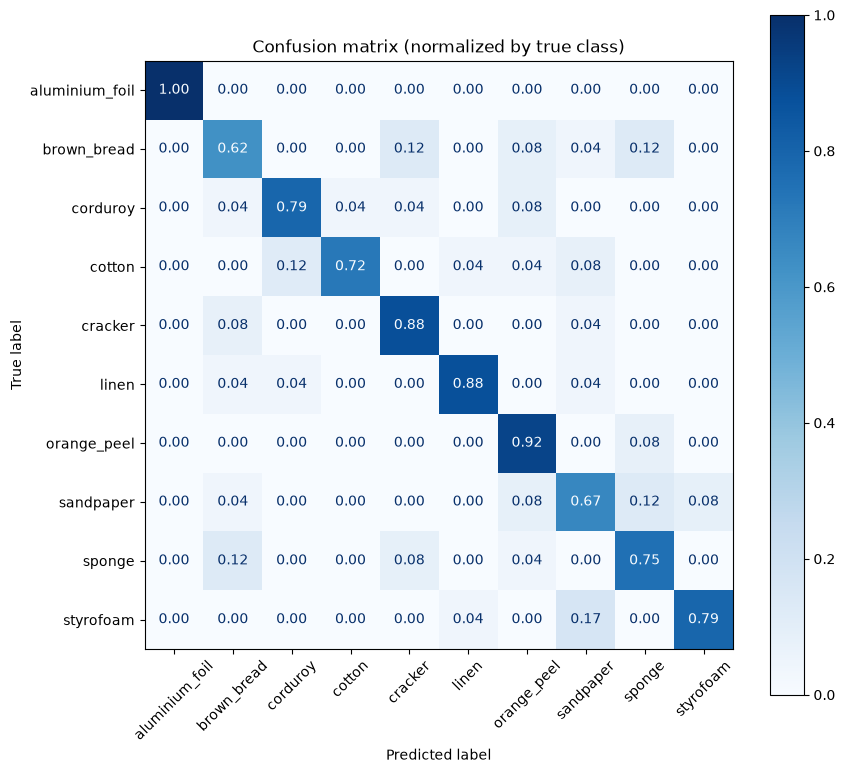

In [61]:
from sklearn.metrics import ConfusionMatrixDisplay

model = search.best_estimator_
y_pred = model.predict(X[idx_test])

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(
    labels[idx_test],
    y_pred,
    labels=CLASSES,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    xticks_rotation=45,
    ax=ax,
)
ax.set_title("Confusion matrix (normalized by true class)")
plt.tight_layout()
plt.show()